---
title: 'Solutions: Flow Matching'
author: Mark Fuge
format:
    html:
        code-fold: true
        code-summary: "Show Solution Code"
---

These are worked solutions to the exercises at the end of the chapter *Flow Matching*.

In [1]:
import sys

import numpy as np
import torch
from torch import nn
from matplotlib import pyplot as plt

sys.path.insert(0, '../part2/gen_models')
from gen_models_utilities import device, create_ring_gaussians

# The chapter's seeds and ring data (the first draw from NumPy's global generator in the chapter)
torch.manual_seed(42)
np.random.seed(42)
data, labels = create_ring_gaussians(n_samples=1000)

### Exercise 1: Straight lines in, curved paths out

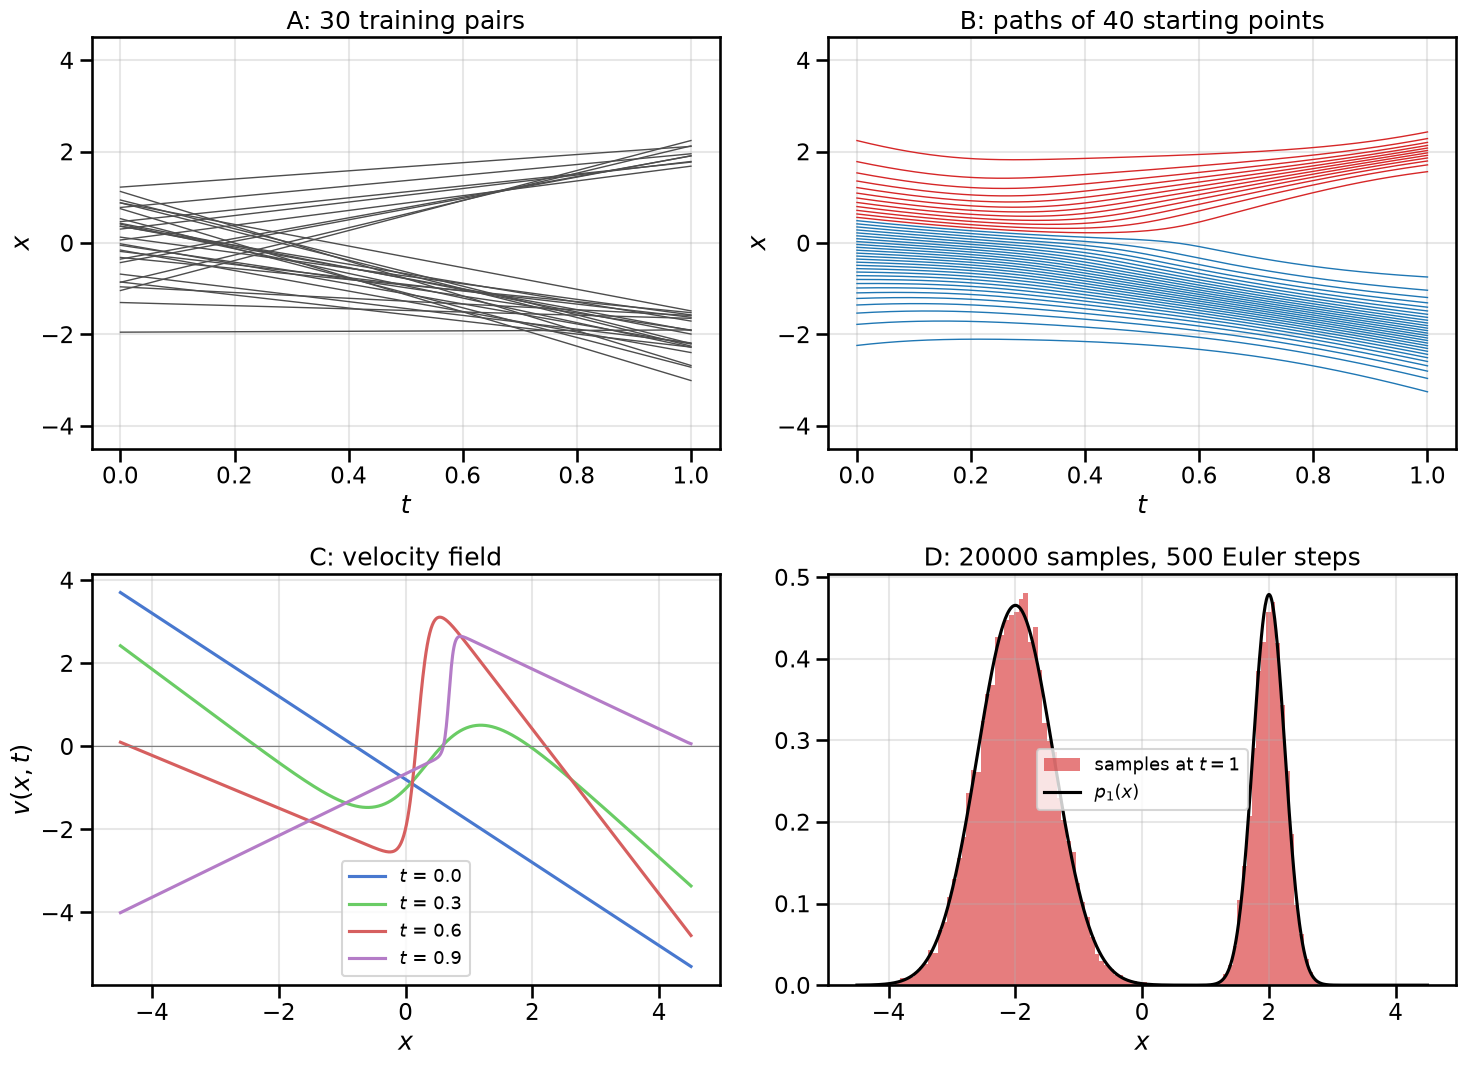

Share of samples in the right mode (x > 0): 0.300 (target 0.30)


In [2]:
# Figure for Exercise 1: the exact flow matching field for a 1D two-mode mixture with a standard normal base
from scipy.stats import norm

EX_SEED = 42
MIX_W = np.array([0.7, 0.3])
MIX_MU = np.array([-2.0, 2.0])
MIX_SD = np.array([0.6, 0.25])
EX1_STEPS = 500     # Euler steps, as in the chapter's sampler
EX1_SAMPLES = 20000
EX1_PATHS = 40
EX1_PAIRS = 30


def mix_pdf(x):
    return (MIX_W * np.exp(-0.5 * ((x[:, None] - MIX_MU) / MIX_SD) ** 2) / (MIX_SD * np.sqrt(2 * np.pi))).sum(axis=1)


def sample_mix(n, rng):
    k = rng.choice(2, size=n, p=MIX_W)
    return MIX_MU[k] + MIX_SD[k] * rng.standard_normal(n)


def v_exact_1d(x, t):
    # The minimizer of the flow matching loss: the average of x1 - x0 over the pairs whose line passes through x at time t
    var = (1 - t) ** 2 + t ** 2 * MIX_SD ** 2          # variance of x_t within each mode
    d = x[:, None] - t * MIX_MU                         # offset of x from each mode's mean of x_t
    log_r = np.log(MIX_W) - 0.5 * d ** 2 / var - 0.5 * np.log(var)
    resp = np.exp(log_r - log_r.max(axis=1, keepdims=True))
    resp /= resp.sum(axis=1, keepdims=True)              # which mode the pair through x is likely heading to
    v_mode = MIX_MU + (t * MIX_SD ** 2 - (1 - t)) / var * d  # average of x1 - x0 over the pairs of that mode
    return (resp * v_mode).sum(axis=1)


def euler_1d(x0, n_steps=EX1_STEPS):
    # The chapter's Euler sampler; returns the whole trajectory, shape (n_steps + 1, len(x0))
    x = x0.copy()
    path = [x.copy()]
    for i in range(n_steps):
        x = x + v_exact_1d(x, i / n_steps) / n_steps
        path.append(x.copy())
    return np.array(path)


rng_ex1 = np.random.default_rng(EX_SEED)
pairs_x0 = rng_ex1.standard_normal(EX1_PAIRS)
pairs_x1 = sample_mix(EX1_PAIRS, rng_ex1)
starts_ex1 = norm.ppf((np.arange(EX1_PATHS) + 0.5) / EX1_PATHS)  # starting points spread evenly over the base
paths_ex1 = euler_1d(starts_ex1)
samples_ex1 = euler_1d(rng_ex1.standard_normal(EX1_SAMPLES))[-1]
t_steps = np.linspace(0, 1, EX1_STEPS + 1)
xs_ex1 = np.linspace(-4.5, 4.5, 901)

fig, axes = plt.subplots(2, 2, figsize=(15, 11))
ax = axes[0, 0]
for a, b in zip(pairs_x0, pairs_x1):
    ax.plot([0, 1], [a, b], color='0.3', linewidth=1)
ax.set_title(f'A: {EX1_PAIRS} training pairs')
ax = axes[0, 1]
for j in range(EX1_PATHS):
    ax.plot(t_steps, paths_ex1[:, j], color='tab:red' if paths_ex1[-1, j] > 0 else 'tab:blue', linewidth=1)
ax.set_title(f'B: paths of {EX1_PATHS} starting points')
for ax in axes[0]:
    ax.set_xlabel('$t$')
    ax.set_ylabel('$x$')
    ax.set_ylim(-4.5, 4.5)
    ax.grid(True, alpha=0.3)
ax = axes[1, 0]
for t_val in [0.0, 0.3, 0.6, 0.9]:
    ax.plot(xs_ex1, v_exact_1d(xs_ex1, t_val), label=f'$t$ = {t_val}')
ax.axhline(0, color='0.5', linewidth=0.8)
ax.set_xlabel('$x$')
ax.set_ylabel('$v(x, t)$')
ax.set_title('C: velocity field')
ax.legend(fontsize=13)
ax.grid(True, alpha=0.3)
ax = axes[1, 1]
ax.hist(samples_ex1, bins=np.linspace(-4.5, 4.5, 121), density=True, color='tab:red', alpha=0.6, label='samples at $t = 1$')
ax.plot(xs_ex1, mix_pdf(xs_ex1), color='k', label='$p_1(x)$')
ax.set_xlabel('$x$')
ax.set_title(f'D: {EX1_SAMPLES} samples, {EX1_STEPS} Euler steps')
ax.legend(loc='center', fontsize=13)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f'Share of samples in the right mode (x > 0): {np.mean(samples_ex1 > 0):.3f} (target {MIX_W[1]:.2f})')

In [3]:
# (a) Two paths that turn around: where they go first and where they end
for x_start in [1.0, -2.5]:
    path = euler_1d(np.array([x_start]))[:, 0]
    k_turn = np.argmin(path) if x_start > 0 else np.argmax(path)
    print(f'start {x_start:+.1f}: turns at x = {path[k_turn]:+.2f} (t = {t_steps[k_turn]:.2f}), ends at x = {path[-1]:+.2f}')

# (b) The field at t = 0 against -0.8 - x, and the split between the two modes
data_mean = (MIX_W * MIX_MU).sum()
print(f'data mean {data_mean:.2f}; largest |v(x, 0) - (data mean - x)| on the plotted grid: '
      f'{np.abs(v_exact_1d(xs_ex1, 0.0) - (data_mean - xs_ex1)).max():.1e}')
x_split = norm.ppf(MIX_W[0])
print(f'70th percentile of the base: x0 = {x_split:.3f}')
pair = euler_1d(np.array([x_split - 0.001, x_split + 0.001]))
for t_val in [0.0, 0.4, 0.5, 0.6, 0.7, 0.8, 1.0]:
    k = int(round(t_val * EX1_STEPS))
    v_pair = v_exact_1d(pair[k], t_val)
    print(f't = {t_val:.1f}: the two paths sit at {pair[k, 0]:+.2f} and {pair[k, 1]:+.2f}, {pair[k, 1] - pair[k, 0]:.3f} apart; '
          f'their velocities differ by {v_pair[1] - v_pair[0]:+.3f}')
dvdx = np.gradient(v_exact_1d(xs_ex1, 0.6), xs_ex1)
print(f'steepest rise of v(x, 0.6) at x = {xs_ex1[np.argmax(dvdx)]:.2f}')

# Every path that starts above the 70th percentile ends in the right mode, every path below it in the left mode
ends_right = paths_ex1[-1] > 0
print('paths sorted by start keep their order at t = 1:', bool(np.all(np.diff(paths_ex1[-1]) > 0)))
print('paths ending in the right mode are exactly those starting above x0 = 0.524:',
      bool(np.all(ends_right == (starts_ex1 > x_split))))
print(f'share of samples in the right mode: {np.mean(samples_ex1 > 0):.3f}')

start +1.0: turns at x = +0.70 (t = 0.28), ends at x = +1.98
start -2.5: turns at x = -2.31 (t = 0.28), ends at x = -3.42
data mean -0.80; largest |v(x, 0) - (data mean - x)| on the plotted grid: 1.8e-15
70th percentile of the base: x0 = 0.524
t = 0.0: the two paths sit at +0.52 and +0.53, 0.002 apart; their velocities differ by -0.002
t = 0.4: the two paths sit at +0.17 and +0.18, 0.003 apart; their velocities differ by +0.013
t = 0.5: the two paths sit at +0.16 and +0.17, 0.005 apart; their velocities differ by +0.051
t = 0.6: the two paths sit at +0.19 and +0.21, 0.019 apart; their velocities differ by +0.308
t = 0.7: the two paths sit at +0.17 and +0.29, 0.128 apart; their velocities differ by +2.372
t = 0.8: the two paths sit at -0.01 and +0.24, 0.255 apart; their velocities differ by +0.109
t = 1.0: the two paths sit at -0.17 and +0.13, 0.294 apart; their velocities differ by +0.294
steepest rise of v(x, 0.6) at x = 0.19
paths sorted by start keep their order at t = 1: True
paths

**(a)** Many training lines pass through a point $(t, x)$. Each line has its own slope $x_1 - x_0$. The network can output only one velocity there. The mean of the slopes gives the smallest squared error over all these lines. So the field that minimizes the loss is the average of $x_1 - x_0$ over all pairs whose line passes through $x$ at time $t$.

The set of pairs through a point changes with $t$. Near $t = 0$, almost any pair can pass through $x$, so the average points toward the data mean. Near $t = 1$, only pairs that end in the nearby mode pass through $x$, so the average points into that mode. The velocity along a path therefore changes over time, and the path bends. The path that starts at $x_0 = 1.0$ first moves left, to 0.70 at $t = 0.28$. Then it turns and ends at 1.98 in the right mode. The path from $x_0 = -2.5$ first moves right, to $-2.31$, and then ends at $-3.42$.

The paths cannot cross because the field is smooth and gives one velocity at each $(t, x)$. For a smooth field, only one solution of $dx/dt = v(x, t)$ passes through a given point. If two paths met, they would be the same path from then on, and also before. The training lines can cross because each one belongs to its own pair. None of them is a path of the field.

**(b)** The start point decides the mode, right from the beginning. Paths cannot cross, as we saw in (a), so the flow keeps the samples in order. The value $x_0 = 0.52$ is the 70th percentile of $\mathcal{N}(0, 1)$. The 70% of base samples below it end in the left mode, and the 30% above it end in the right mode. All 40 paths in panel B follow this rule.

The field does not show this at first. At $t = 0$, the point $x_t$ is the base sample $x_0$ itself. With independent pairs, $x_0$ tells us nothing about its partner $x_1$. So the average of $x_1 - x_0$ over the pairs through $x$ is $\mathbb{E}[x_1] - x = -0.8 - x$. Here $\mathbb{E}[x_1] = 0.7 \cdot (-2) + 0.3 \cdot 2 = -0.8$ is the data mean. Every sample heads for the data mean, whichever mode it will end in.

The field bends away from the straight line $-0.8 - x$ early: by $t = 0.3$ it already rises between the modes. From about $t = 0.2$ on, its slope across the split is positive, so it starts to push the two groups apart. At first the push is weak. Two paths that start 0.002 apart, one on each side of $x_0 = 0.52$, are still only 0.003 apart at $t = 0.4$. The vector field then becomes stronger between $t = 0.5$ and $t = 0.7$, where the slope in the velocity field across the split reaches 16 to 25. By then the paths are 0.13 apart ($t = 0.7$) and 0.25 apart ($t = 0.8$). Early on, the pairs whose lines pass near the split still come from both modes, so their average can only push the groups apart gently. Later, the pairs through each side come mostly from one mode.

**(c)** The flow moves probability mass without creating or losing any. So the share of samples that ends in a mode equals the share of base mass that moves to each mode following the flow field. The field is an average over pairs drawn with the true weights 0.7 and 0.3. As we saw in (b), it sends the lower 70% of the base to the left mode. Because this is a deterministic flow, there is no "jumping" across the low-density region between the modes, like we saw with the Langevin Sampling, and it is also fairly straightforward for the flow to force samples to deterministically obey the 30/70 split (since paths cannot cross each other).

In contrast, Langevin sampling using the score function must attempt to find the weights by itself, since the score function only describes the local shape of $\log p$ near each point. It carries no information about how much probability mass sits in a mode far away. Langevin sampling relies on its random steps to move enough points between the modes to reach the correct mixture, but it cannot guarantee this. With $\alpha = 0.01$, a point can only reach the other mode by crossing the low probability gap, and we saw that this rarely happened with that $\alpha$, so the probability mass stayed roughly in the modes where the points started. With $\alpha = 0.1$, the step was too large for the narrow right mode, and thus the updates threw its points far beyond its width, causing points to leak into the wide left mode. Once there very few of them ever come back, and unlike in Flow Matching, the Langevin Sampler didn't have a direct enforcement mechanism to split the points in the right proportions.

### Exercise 2: Find the bug in the sampler

In [ ]:
@torch.no_grad()
def sample_flow(model, n_samples=1000, n_steps=100):
    """Euler sampler for a flow trained with a standard Gaussian base (the chapter's generate_with_ode_solver, Gaussian case)."""
    model.eval()

    # Start with pure noise
    x = torch.rand(n_samples, 2, device=device)

    dt = 1. / n_steps
    for i in range(n_steps):
        t = torch.full((n_samples, 1), i / n_steps, device=device)
        v = model(x, t)
        x = x + v * dt
    return x.cpu().numpy()

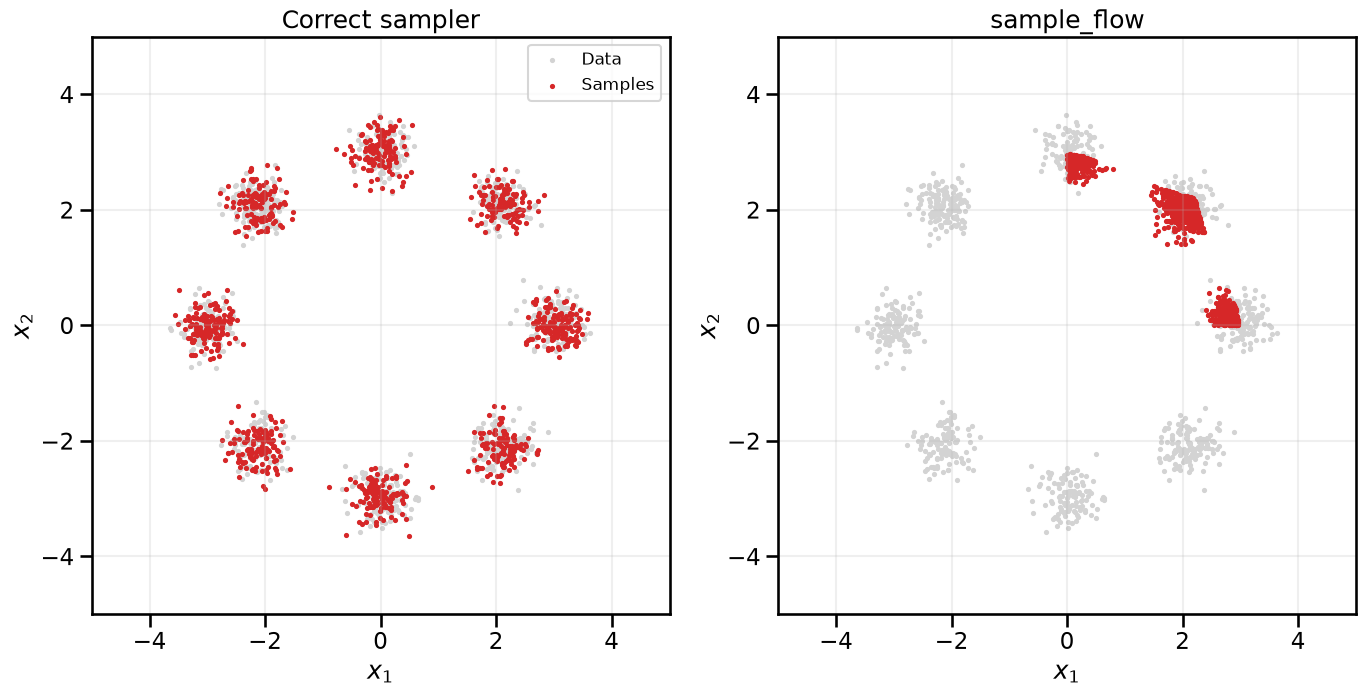

Samples per mode (mode k sits at 45 k degrees):
                   0     1     2     3     4     5     6     7
Correct          140   115   125   128   135   119   125   113
sample_flow      203   575   222     0     0     0     0     0


In [5]:
# Figure for Exercise 2: the exact ring field, sampled with a correct sampler and with sample_flow above
EX_SEED = 42


class RingVelocityField(nn.Module):
    """Exact minimizer of the flow matching loss for the chapter's ring (8 modes, radius 3, std 0.25),
    with a standard Gaussian base and independent pairs."""

    def __init__(self, n_modes=8, radius=3.0, mode_std=0.25):
        super().__init__()
        angles = torch.arange(n_modes) * 2 * np.pi / n_modes
        self.centers = radius * torch.stack([torch.cos(angles), torch.sin(angles)], dim=1)
        self.mode_std = mode_std

    def forward(self, x, t):
        mu = self.centers.to(x.device)
        var = (1 - t) ** 2 + t ** 2 * self.mode_std ** 2       # [n, 1]
        d = x[:, None, :] - t[:, None, :] * mu[None]           # [n, modes, 2]
        resp = torch.softmax(-0.5 * (d ** 2).sum(-1) / var, dim=1)
        v_mode = mu[None] + ((t * self.mode_std ** 2 - (1 - t)) / var)[:, :, None] * d
        return (resp[..., None] * v_mode).sum(1)


@torch.no_grad()
def sample_flow_correct(model, n_samples=1000, n_steps=100):
    model.eval()
    x = torch.randn(n_samples, 2, device=device)
    dt = 1. / n_steps
    for i in range(n_steps):
        t = torch.full((n_samples, 1), i / n_steps, device=device)
        x = x + model(x, t) * dt
    return x.cpu().numpy()


def count_per_mode(x, n_modes=8):
    # Assign each sample to the nearest mode direction (mode k sits at 45 k degrees)
    k = np.round(np.arctan2(x[:, 1], x[:, 0]) / (2 * np.pi / n_modes)).astype(int) % n_modes
    return np.bincount(k, minlength=n_modes)


ring_field = RingVelocityField()
torch.manual_seed(EX_SEED)
samples_correct = sample_flow_correct(ring_field)
torch.manual_seed(EX_SEED)
samples_buggy = sample_flow(ring_field)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, x, title in [(axes[0], samples_correct, 'Correct sampler'), (axes[1], samples_buggy, 'sample_flow')]:
    ax.scatter(data[:, 0], data[:, 1], s=5, color='lightgrey', label='Data')
    ax.scatter(x[:, 0], x[:, 1], s=5, color='tab:red', label='Samples')
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.set_aspect('equal')
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    ax.set_title(title)
    ax.grid(True, alpha=0.2)
axes[0].legend(loc='upper right', fontsize=12)
plt.tight_layout()
plt.show()

print('Samples per mode (mode k sits at 45 k degrees):')
print(f"{'':14s}" + ''.join(f'{k:>6d}' for k in range(8)))
for name, x in [('Correct', samples_correct), ('sample_flow', samples_buggy)]:
    print(f'{name:14s}' + ''.join(f'{c:6d}' for c in count_per_mode(x)))

In [6]:
# (a) Each start point ends in the mode whose 45-degree wedge contains the direction of the start point
def wedge_of(x, n_modes=8):
    return np.round(np.arctan2(x[:, 1], x[:, 0]) / (2 * np.pi / n_modes)).astype(int) % n_modes


torch.manual_seed(EX_SEED)
starts_buggy = torch.rand(1000, 2, device=device).cpu().numpy()  # the same start points sample_flow drew
torch.manual_seed(EX_SEED)
starts_gauss = torch.randn(1000, 2, device=device).cpu().numpy()  # the same start points the correct sampler drew
print('unit-square starts ending in the mode of their wedge:', np.mean(wedge_of(starts_buggy) == wedge_of(samples_buggy)))
print('Gaussian starts ending in the mode of their wedge:   ', np.mean(wedge_of(starts_gauss) == wedge_of(samples_correct)))

# (b) Share of the unit square in each wedge
share_side = np.tan(np.deg2rad(22.5)) / 2
print(f'expected shares of modes 0, 1, 2: {share_side:.3f}, {1 - 2 * share_side:.3f}, {share_side:.3f}')
print('observed shares:                  ', ', '.join(f'{c / 1000:.3f}' for c in count_per_mode(samples_buggy)[:3]))

# (c) Where the unit square sits in the base, and how far the samples spread within each mode
print(f'share of the base N(0, I) inside the unit square: {(norm.cdf(1) - 0.5) ** 2:.3f}')
print('                 distance from origin: mean, std')
for k in range(3):
    r_bug = np.linalg.norm(samples_buggy[wedge_of(samples_buggy) == k], axis=1)
    r_ok = np.linalg.norm(samples_correct[wedge_of(samples_correct) == k], axis=1)
    print(f'mode {k}: sample_flow {r_bug.mean():.2f}, {r_bug.std():.2f}   correct {r_ok.mean():.2f}, {r_ok.std():.2f}')

unit-square starts ending in the mode of their wedge: 1.0
Gaussian starts ending in the mode of their wedge:    1.0
expected shares of modes 0, 1, 2: 0.207, 0.586, 0.207
observed shares:                   0.203, 0.575, 0.222
share of the base N(0, I) inside the unit square: 0.117
                 distance from origin: mean, std
mode 0: sample_flow 2.78, 0.13   correct 3.05, 0.24
mode 1: sample_flow 2.86, 0.15   correct 3.00, 0.22
mode 2: sample_flow 2.81, 0.12   correct 3.03, 0.27


**(a)** The wrong line is `x = torch.rand(n_samples, 2, device=device)`. It draws the start points uniformly from the unit square $[0, 1]^2$ instead of from $\mathcal{N}(0, I)$. The correct sampler uses `torch.randn`, as in the left panel. The field was built for the Gaussian base. It moves each start point to a fixed end point. Because of the ring's symmetry, it sends the base points in each 45-degree wedge around a mode's direction to that mode. The reason is that the field is symmetric about each ray halfway between two modes. A sample on such a ray stays on it, so no path can cross it. All 1000 start points, from the square and from the Gaussian, end in the mode of their wedge. The unit square holds only directions between 0 and 90 degrees. These directions lie in the wedges of modes 0, 1 and 2.

**(b)** Mode 1's wedge runs from 22.5 to 67.5 degrees. It covers the whole square except two triangles. One triangle lies below the ray at 22.5 degrees, and the other lies above the ray at 67.5 degrees. Each triangle has area $\tan(22.5^\circ)/2 = 0.207$. So mode 1 should get $1 - \tan(22.5^\circ) = 0.586$ of the samples, and modes 0 and 2 should get 0.207 each. The observed shares are 0.575, 0.203 and 0.222. They agree with this within sampling noise.

**(c)** The flow is a smooth, one-to-one map from the base to the data. Each piece of the base goes to its own piece of the data. To fill the whole data distribution, the flow needs the whole base. For the Gaussian base, almost all of the mass lies between $-3$ and $3$ on each axis. In contrast, the unit square is a small piece of the base, between 0 and 1 on both axes. It holds only 0.117 of the mass of $\mathcal{N}(0, I)$, and all its points lie within $\sqrt{2}$ of the origin. In mode 0, the samples of `sample_flow` sit at a mean distance of 2.78 from the origin, with a standard deviation of 0.13. For the correct sampler, these numbers are 3.05 and 0.24. The sampler is deterministic and never compares its samples with the data. So it cannot tell that its start points have the wrong spread. It moves each start point to the same place it would move that point if it came from the Gaussian.

### Exercise 3: Conditioning changes the average

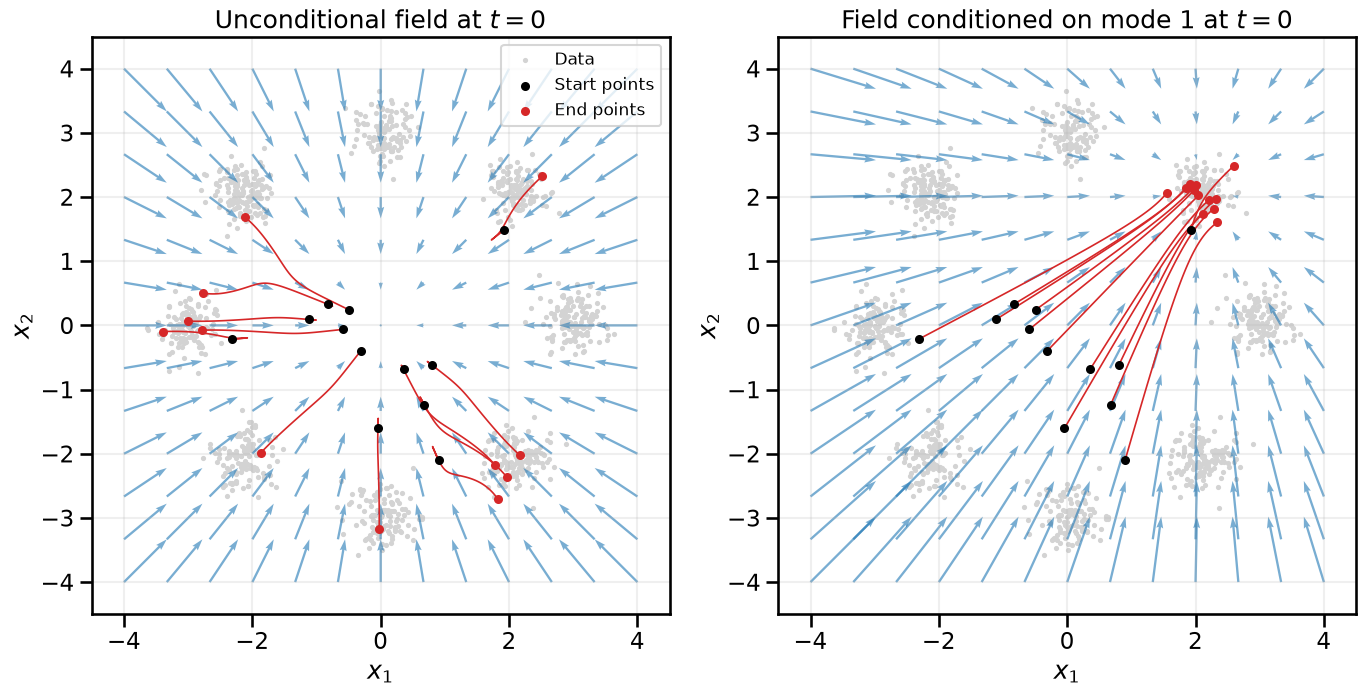

In [7]:
# Figure for Exercise 3: the exact unconditional ring field and the exact field conditioned on one mode, at t = 0
EX_SEED = 42
EX3_MODE = 1          # the mode the conditional field is conditioned on
EX3_PATHS = 12        # number of start points whose paths are drawn
EX3_STEPS = 100       # Euler steps, as in Exercise 2


class OneModeVelocityField(RingVelocityField):
    """Exact field for the ring conditioned on one mode: the target is a single Gaussian at that mode's center."""

    def __init__(self, mode, **kwargs):
        super().__init__(**kwargs)
        self.centers = self.centers[mode:mode + 1]


@torch.no_grad()
def euler_paths(field, x0, n_steps=EX3_STEPS):
    # Euler integration from the start points x0; returns the trajectory, shape (n_steps + 1, n, 2)
    x = x0.clone()
    path = [x.clone()]
    for i in range(n_steps):
        t = torch.full((x.shape[0], 1), i / n_steps)
        x = x + field(x, t) / n_steps
        path.append(x.clone())
    return torch.stack(path).numpy()


uncond_field = RingVelocityField()
cond_field = OneModeVelocityField(EX3_MODE)
torch.manual_seed(EX_SEED)
starts_ex3 = torch.randn(EX3_PATHS, 2)
grid_1d = torch.linspace(-4, 4, 13)
gx, gy = torch.meshgrid(grid_1d, grid_1d, indexing='xy')
grid_ex3 = torch.stack([gx.flatten(), gy.flatten()], dim=1)
t0 = torch.zeros(grid_ex3.shape[0], 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
for ax, field, title in [(axes[0], uncond_field, 'Unconditional field at $t = 0$'),
                         (axes[1], cond_field, f'Field conditioned on mode {EX3_MODE} at $t = 0$')]:
    with torch.no_grad():
        v0 = field(grid_ex3, t0).numpy()
    paths = euler_paths(field, starts_ex3)
    ax.scatter(data[:, 0], data[:, 1], s=5, color='lightgrey', label='Data')
    ax.quiver(grid_ex3[:, 0], grid_ex3[:, 1], v0[:, 0], v0[:, 1], color='tab:blue', alpha=0.6,
              angles='xy', scale_units='xy', scale=6, width=0.004)
    for j in range(EX3_PATHS):
        ax.plot(paths[:, j, 0], paths[:, j, 1], color='tab:red', linewidth=1.2)
    ax.scatter(paths[0, :, 0], paths[0, :, 1], s=25, color='k', zorder=3, label='Start points')
    ax.scatter(paths[-1, :, 0], paths[-1, :, 1], s=25, color='tab:red', zorder=3, label='End points')
    ax.set_xlim(-4.5, 4.5)
    ax.set_ylim(-4.5, 4.5)
    ax.set_aspect('equal')
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    ax.set_title(title)
    ax.grid(True, alpha=0.2)
axes[0].legend(loc='upper right', fontsize=12)
plt.tight_layout()
plt.show()

In [8]:
# (a) At t = 0 the unconditional field is E[x1] - x = -x, because the ring's centers average to the origin
grid_v_uncond = uncond_field(grid_ex3, t0)
print(f'distance of the mean of the eight mode centers from the origin: {uncond_field.centers.mean(0).norm():.1e}')
print(f'largest |v(x, 0) - (-x)| on the grid: {(grid_v_uncond + grid_ex3).abs().max():.1e}')
print(f'distance from the origin to the closest of the {len(data)} data points: {np.linalg.norm(data, axis=1).min():.2f}')

# The unconditional paths first move toward the center, then turn out to a mode
paths_uncond = euler_paths(uncond_field, starts_ex3)
r_paths = np.linalg.norm(paths_uncond, axis=2)
print(f'mean distance of the 12 paths from the origin: {r_paths[0].mean():.2f} at t = 0, '
      f'{r_paths.min(axis=0).mean():.2f} at their closest, {r_paths[-1].mean():.2f} at t = 1')

# (b) Conditioned on mode 1, the field at t = 0 is mu_1 - x: it points at mode 1 from every x
mu_1 = cond_field.centers[0]
grid_v_cond = cond_field(grid_ex3, t0)
print(f'largest |v(x, 0 | mode 1) - (mu_1 - x)| on the grid: {(grid_v_cond - (mu_1 - grid_ex3)).abs().max():.1e}')
# The unconditional field at t = 0 is the average of the eight one-mode fields: each mode keeps 1/8 of the pairs
v_modes = torch.stack([OneModeVelocityField(k)(grid_ex3, t0) for k in range(8)])
print(f'largest |unconditional - average of the eight one-mode fields| at t = 0: {(grid_v_uncond - v_modes.mean(0)).abs().max():.1e}')
paths_cond = euler_paths(cond_field, starts_ex3)
print(f'conditional paths: largest distance of an end point from mode 1: {np.linalg.norm(paths_cond[-1] - mu_1.numpy(), axis=1).max():.2f}')

distance of the mean of the eight mode centers from the origin: 1.1e-07
largest |v(x, 0) - (-x)| on the grid: 2.4e-07
distance from the origin to the closest of the 1000 data points: 2.25
mean distance of the 12 paths from the origin: 1.29 at t = 0, 1.16 at their closest, 3.01 at t = 1
largest |v(x, 0 | mode 1) - (mu_1 - x)| on the grid: 0.0e+00
largest |unconditional - average of the eight one-mode fields| at t = 0: 2.4e-07
conditional paths: largest distance of an end point from mode 1: 0.60


**(a)** At $t = 0$, the point $x_t$ is the base sample $x_0$ itself. With independent pairs, it tells us nothing about its target/partner $x_1$. So at $t=0$ the average of $x_1 - x_0$ over the pairs through $x$ is $\mathbb{E}[x_1] - x$. The eight modes have equal weights and sit symmetrically on the ring. So $\mathbb{E}[x_1]$ is the center of the ring, and the field is $-x$. Every arrow points at the center of the ring. Interestingly, even though the flow field points to the origin, the closest of the 1000 data points is actually 2.25 away from the origin! The data mean is essentially a compromise between the eight modes, even though there is actually no data at the origin itself. The unconditional paths first move a little toward the center, from a mean distance of 1.29 to 1.16 from the origin. Later, as $t \rightarrow 1$, each point turns toward a mode, because the pairs whose lines pass through its position now come mostly from that mode.

**(b)** Conditioning on mode 1 keeps only the pairs whose data point $x_1$ comes from mode 1. It removes the pairs that end in the other seven modes. The average of $x_1 - x_0$ at $t = 0$ is then $\mathbb{E}[x_1 \mid \text{mode } 1] - x = \mu_1 - x$, which points from every $x$ straight at the center $\mu_1$ of mode 1. The unconditional field at $t = 0$ is the average of the eight one-mode fields, $\frac{1}{8}\sum_k (\mu_k - x) = -x$. In that average, the pull toward each mode is cancelled by the pulls toward the others. The conditional field has no such cancellation. So its paths are nearly straight lines into mode 1, and all 12 end within 0.60 of its center.